# Análisis Exploratorio de Datos (EDA)

Exploraremos los datos limpios para comprender las relaciones entre las variables de supervivenia.

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('data/titanic_clean.csv')
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


# Supervivencia por Género

C:\Users\jose2\AppData\Local\Temp\ipykernel_22040\1505180528.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=df, palette='viridis')


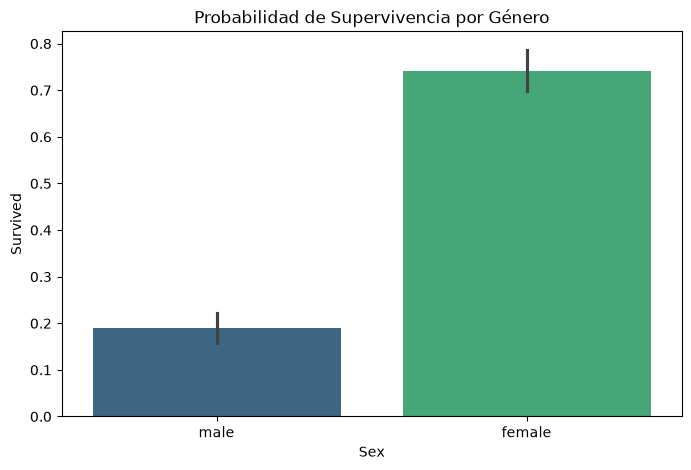

In [8]:
plt.figure(figsize=(8,5))
sns.barplot(x='Sex', y='Survived', data=df, palette='viridis')
plt.title('Probabilidad de Supervivencia por Género')
plt.show()

C:\Users\jose2\AppData\Local\Temp\ipykernel_22040\3078854192.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y= 'Survived', data=df, palette='magma')


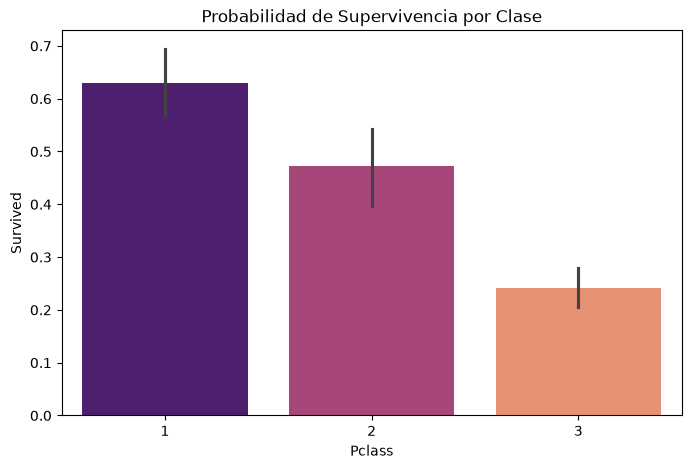

In [9]:
plt.figure(figsize=(8,5))
sns.barplot(x='Pclass', y= 'Survived', data=df, palette='magma')
plt.title('Probabilidad de Supervivencia por Clase')
plt.show()

# Distribución de Edades

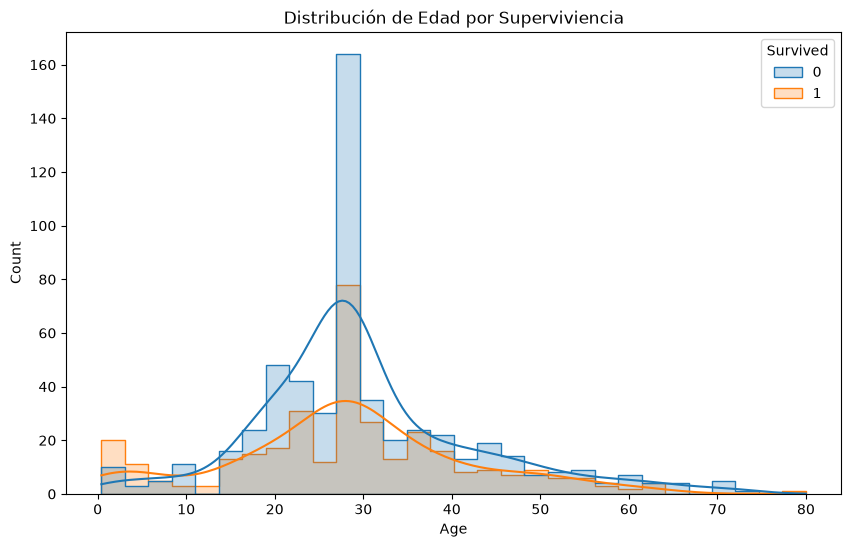

In [10]:
plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Age', hue= 'Survived', kde=True, element='step')
plt.title('Distribución de Edad por Superviviencia')
plt.show()

In [11]:
df['Sex'] = df['Sex'].map({'male': 0, 'female':1})

df = pd.get_dummies(df, columns=['Embarked'], prefix='Emb')

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Emb_C,Emb_Q,Emb_S
0,0,3,0,22.0,1,0,7.2500,False,False,True
1,1,1,1,38.0,1,0,71.2833,True,False,False
2,1,3,1,26.0,0,0,7.9250,False,False,True
3,1,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,0,35.0,0,0,8.0500,False,False,True


In [14]:
df.to_csv('data/titanic_feature.csv', index= False)

print("Datos guardados en data/titanic_feature.csv")

Datos guardados en data/titanic_feature.csv


In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

df = pd.read_csv('data/titanic_feature.csv')

x = df.drop('Survived', axis=1)
y = df['Survived']


In [28]:
print("Dimensiones de x:", x.shape)
print("Dimensiones de y:", y.shape)

print("\nPrimeras cinco filas de x:")
display(x.head())

print("\nPrimeros cinco valores de y:")
display(y.head())

Dimensiones de x: (891, 9)
Dimensiones de y: (891,)

Primeras cinco filas de x:


,Pclass,Sex,Age,SibSp,Parch,Fare,Emb_C,Emb_Q,Emb_S
0,3,0,22.0,1,0,7.2500,False,False,True
1,1,1,38.0,1,0,71.2833,True,False,False
2,3,1,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,3,0,35.0,0,0,8.0500,False,False,True



Primeros cinco valores de y:


0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [30]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

print("Datos de entrenamiento:", x_train.shape)
print("Datos de prueba:", x_test.shape)

Datos de entrenamiento: (712, 9)
Datos de prueba: (179, 9)


In [31]:
modelo_rf = RandomForestClassifier(random_state=42)

modelo_rf.fit(x_train, y_train)

print("Modelo Random Forest entrenado correctamente.")

Modelo Random Forest entrenado correctamente.


In [32]:
modelo_lr = LogisticRegression(max_iter=1000)

modelo_lr.fit(x_train, y_train)

print("Modelo de Regresión Logística entrenado correctamente.")

Modelo de Regresión Logística entrenado correctamente.


In [33]:
y_pred_rf = modelo_rf.predict(x_test)
y_pred_lr = modelo_lr.predict(x_test)

print("Primeras 10 predicciones de Random Forest:")
print(y_pred_rf[:10])

print("\nPrimeras 10 predicciones de Regresión Logística:")
print(y_pred_lr[:10])

Primeras 10 predicciones de Random Forest:
[0 0 0 1 0 1 1 0 1 1]

Primeras 10 predicciones de Regresión Logística:
[0 0 0 1 1 1 1 0 1 1]


In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

print("RANDOM FOREST")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))

print("\nREGRESIÓN LOGÍSTICA")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr), 4))

RANDOM FOREST
Accuracy: 0.8101
Precision: 0.7703
Recall: 0.7703

REGRESIÓN LOGÍSTICA
Accuracy: 0.8101
Precision: 0.7857
Recall: 0.7432


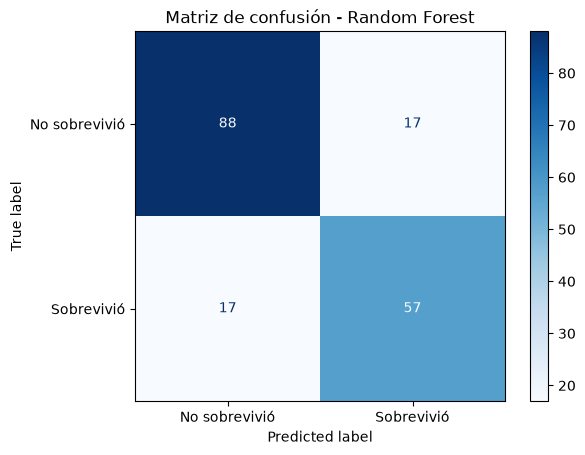

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_rf = confusion_matrix(y_test, y_pred_rf)

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['No sobrevivió', 'Sobrevivió']
)

disp_rf.plot(cmap='Blues')
plt.title('Matriz de confusión - Random Forest')
plt.show()

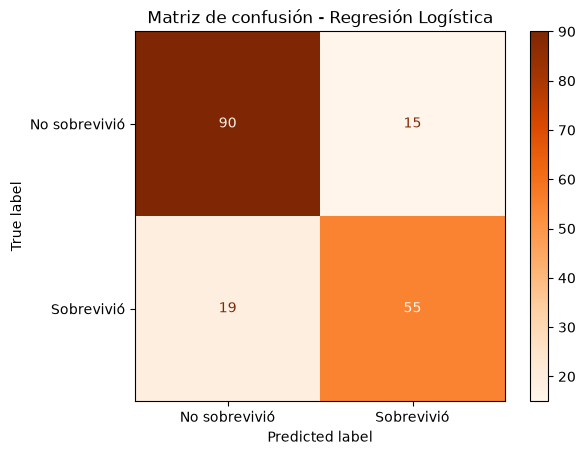

In [36]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=['No sobrevivió', 'Sobrevivió']
)

disp_lr.plot(cmap='Oranges')
plt.title('Matriz de confusión - Regresión Logística')
plt.show()

In [37]:
from sklearn.metrics import classification_report

print("RANDOM FOREST")
print(classification_report(y_test, y_pred_rf,
                            target_names=['No sobrevivió', 'Sobrevivió']))

print("\nREGRESIÓN LOGÍSTICA")
print(classification_report(y_test, y_pred_lr,
                            target_names=['No sobrevivió', 'Sobrevivió']))

RANDOM FOREST
               precision    recall  f1-score   support

No sobrevivió       0.84      0.84      0.84       105
   Sobrevivió       0.77      0.77      0.77        74

     accuracy                           0.81       179
    macro avg       0.80      0.80      0.80       179
 weighted avg       0.81      0.81      0.81       179


REGRESIÓN LOGÍSTICA
               precision    recall  f1-score   support

No sobrevivió       0.83      0.86      0.84       105
   Sobrevivió       0.79      0.74      0.76        74

     accuracy                           0.81       179
    macro avg       0.81      0.80      0.80       179
 weighted avg       0.81      0.81      0.81       179

